<a href="https://colab.research.google.com/github/villsydican/machine-learning-project/blob/main/Chart_annalysis_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import io
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from google.auth import default
from PIL import Image

# 1. Authenticate & Build Drive API
auth.authenticate_user()
creds, _ = default()
drive_service = build('drive', 'v3', credentials=creds)

# 2. Path to your manually created dataset folder
output_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'

def download_and_slice(file_id, file_name, rows, cols, label_mapping, prefix):
    print(f"📥 Downloading: {file_name}...")
    request = drive_service.files().get_media(fileId=file_id)
    local_path = f"/tmp/{file_id}.jpg"

    with open(local_path, 'wb') as fh:
        downloader = MediaIoBaseDownload(fh, request)
        done = False
        while not done:
            status, done = downloader.next_chunk()

    img = Image.open(local_path).convert('RGB')
    w, h = img.size
    cell_w, cell_h = w / cols, h / rows
    count = 0

    for r in range(rows):
        for c in range(cols):
            label = label_mapping.get((r, c))
            if not label:
                continue
            crop = img.crop((
                int((c + 0.08) * cell_w), int((r + 0.18) * cell_h),
                int((c + 0.92) * cell_w), int((r + 0.78) * cell_h)
            )).resize((128, 128))

            save_path = os.path.join(output_dir, label, f"{prefix}_r{r}_c{c}.jpg")
            crop.save(save_path)
            count += 1

    print(f"✅ Sliced & sorted {count} tiles from {file_name}")

# 3. Process each sheet into your manual folders
download_and_slice(
    "1BViimj3mJ-lnL-M79d0QkfOv56AX2BrK", "Bullish candlestick pattern.jpg",
    3, 3, {(r, c): 'buy' for r in range(3) for c in range(3)}, "bullish_9"
)

download_and_slice(
    "1Vkj8OA80pGCvJO8sIN1QY_MP9jEHB1yA", "Candlestick signals",
    2, 4, {(0,0): 'buy', (0,1): 'sell', (0,2): 'sell', (0,3): 'sell', (1,0): 'buy', (1,1): 'buy', (1,2): 'buy', (1,3): 'hold'}, "signals_8"
)

download_and_slice(
    "1GLPPljf91i74zHnMfGtUixI4g8CoIyZr", "TRADING PSYCHOLOGY.jpg",
    4, 4, {(0,0): 'buy', (0,1): 'sell', (0,2): 'buy', (0,3): 'sell', (1,0): 'sell', (1,1): 'buy', (1,2): 'sell', (1,3): 'sell', (2,0): 'buy', (2,1): 'sell', (2,2): 'sell', (2,3): 'sell', (3,0): 'buy', (3,1): 'sell', (3,2): 'buy', (3,3): 'sell'}, "psych_16"
)

download_and_slice(
    "1kj43Dk9YyS9stuEWuG70bDoAbOY7PpmO", "Take Your Binary Options Trading",
    4, 4, {(0,0): 'buy', (0,1): 'sell', (0,2): 'buy', (0,3): 'buy', (1,0): 'sell', (1,1): 'buy', (1,2): 'sell', (1,3): 'sell', (2,0): 'buy', (2,1): 'sell', (2,2): 'buy', (2,3): 'sell', (3,0): 'buy', (3,1): 'sell', (3,2): 'buy', (3,3): 'sell'}, "binary_16"
)

download_and_slice(
    "15sUVHLacRm-3-AzpLHP0CwswZl22p2bD", "Trade Smarter with Our Binary Options Strategy PDF.jpg",
    3, 5, {(r, c): 'sell' for r in range(3) for c in range(5)}, "bearish_15"
)

print("\n🎉 Population complete! Folder counts:")
for cls in ['buy', 'sell', 'hold']:
    print(f"📂 {cls}/ -> {len(os.listdir(os.path.join(output_dir, cls)))} images")

In [18]:
#Generating the images using python
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

output_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'
for cls in ['buy', 'sell', 'hold']:
  os.makedirs(os.path.join(output_dir, cls), exist_ok=True)

def render_candles(candles, save_path, dark_mode=False):
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  bg_color = '#12161c' if dark_mode else '#ffffff'
  bull_color = '#26a69a' if dark_mode else '#16a34a'
  bear_color = '#ef5350' if dark_mode else '#dc2626'
  fig.patch.set_facecolor(bg_color)
  ax.set_facecolor(bg_color)
  for idx, (o, h, l, c) in enumerate(candles):
    color = bull_color if c >= o else bear_color
    #Wick generation
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    #Body generation
    lower = min(o, c)
    height = max(abs(c - o), 0.15) #Minimum visible thickness for Doji
    react = Rectangle((idx - 0.28, lower), 0.56, height, facecolor=color, edgecolor=color, zorder=2)
    ax.add_patch(react)
  all_lows = [x[2] for x in candles]
  all_highs = [x[1] for x in candles]
  pad = (max(all_highs) - min(all_lows)) * 0.15 + 0.5
  ax.set_ylim(min(all_lows) - pad, max(all_highs) + pad)
  ax.set_xlim(-0.7, len(candles) - 0.3)
  ax.axis('off')
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
  fig.savefig(save_path, dpi=100, facecolor=bg_color)
  plt.close(fig)

# Pattern Generators (each building 4 trend candles + key signal candle)
def generate_buy_pattern():
  pattern_type = random.choice(['hammer', 'bullish_engulfing', 'morning_star', 'three_white_soldiers'])
  price = random.uniform(50, 100)
  candles = []
  if pattern_type == 'hammer':
    # 4 bearish downtrend candles + long lower-wick hammer
    for _ in range (4):
      o = price
      c = o - random.uniform(1.2, 3.0)
      h = o + random.uniform(0.2, 1.0)
      l = c - random.uniform(0.2, 1.0)
      candles.append((o, h, l, c))
      price = c
    o = price
    c = o + random.uniform(0.4, 1.2)
    h = c + random.uniform(0.0, 0.3)
    l = o - random.uniform(3.5, 6.5)
    candles.append ((o, h, l, c))
  elif pattern_type == 'bullish_engulfing':
    # 3 downtrend + 1 small red + 1 large green engulfing candle
    for _ in range (3):
      o = price
      c = o - random.uniform(1.0, 2.5)
      candles.append((o, o + 0.6, c - 0.6, c))
      price = c
    o1 = price
    c1 = o1 - random.uniform(0.8, 1.6)
    candles.append((o1, o1 + 0.4, c1 - 0.4, c1))
    o2 = c1 - random.uniform(0.1, 0.4)
    c2 = o1 + random.uniform(1.0, 2.5)
    candles.append((o2, c2 + 0.5, o2 - 0.4, c2))

  elif pattern_type == 'morning_star':
    # 2 downtrend + 1 big red + 1 small star + big green
    for _ in range (2):
      o = price
      c = o - random.uniform(1.0, 2.0)
      candles.append ((o, o + 0.5, c - 0.5, c))
      price = c
    o1, c1 = price, price - random.uniform(2.5, 4.0)
    candles.append((o1, o1 + 0.4, c1 - 0.4, c1))
    o2 = c1 - random.uniform(0.2, 0.6)
    c2 = o2 + random.uniform(-0.3, 0.3)
    candles.append((o2, max(o2, c2) + 0.7, min(o2, c2) - 0.7, c2))
    o3 = max(o2, c2) + 0.2
    c3 = o1 - random.uniform(0.0, 0.8)
    candles.append((o3, c3 + 0.5, o3 - 0.3, c3))
  else: # drawing three white soldiers
    for _ in range (2):
      o = price
      c = o - random.uniform(1.2, 2.5)
      candles.append((o, o + 0.5, c - 0.5, c))
      price = c
    for _ in range (3):
      o = price + random.uniform(0.1, 0.4)
      c = o + random.uniform(1.8, 3.2)
      candles.append((o, c + 0.4, o - 0.3, c))
      price = c

  return candles

def generate_sell_pattern():
  pattern_type = random.choice(['shooting_star', 'bearish_engulfing', 'evening_star', 'three_black_crows'])
  price = random.uniform(50, 100)
  candles = []

  if pattern_type == 'shooting_star':
    for _ in range(4):
      o = price
      c = o + random.uniform(1.2, 3.0)
      h = c + random.uniform(0.2, 1.0)
      l = o - random.uniform(0.2, 1.0)
      candles.append((o, h, l, c ))
      price = c
    o = price
    c  = o - random.uniform(0.4, 1.2)
    h = o + random.uniform(3.5, 6.5)
    l = c - random.uniform(0.0, 0.3)
    candles.append((o, h, l, c))
  elif pattern_type == 'bearish_engulfing' :
    for _ in range (3):
      o = price
      c = o + random.uniform(1.0, 2.5)
      candles.append((o, c + 0.6, o - 0.6, c))
      price = c
    o1 =  price
    c1 = o1 + random.uniform(0.8, 1.6)
    candles.append((o1, c1 + 0.4, o1 - 0.4, c1 ))
    o2 = c1 + random.uniform(0.1, 0.4)
    c2 = o1 - random.uniform(1.0, 2.5)
    candles.append((o2, o2 + 0.4, c2 - 0.5, c2))
  elif pattern_type == 'evening_star':
    for _ in range(2):
      o = price
      c = o + random.uniform(1.0, 2.0)
      candles.append((o, c + 0.5, o - 0.5, c)) # Fixed undefined o1 to o
      price = c
    o1, c1 = price, price + random.uniform(2.5, 4.0)
    candles.append((o1, c1 + 0.4, o1 - 0.4, c1))
    o2 = c1 + random.uniform(0.2, 0.6)
    c2 = o2 + random.uniform(-0.3, 0.3)
    candles.append((o2, max(o2, c2) + 0.7, min(o2, c2) - 0.7, c2))
    o3 = min(o2, c2) - 0.2
    c3 = o1 + random.uniform(0.0, 0.8)
    candles.append((o3, o3 + 0.3, c3 - 0.5, c3))
  else : # three_black_crows
    for _ in range (2):
      o = price
      c = o + random.uniform(0.1, 0.4)
      candles.append((o, o + 0.3, c - 0.4, c))
      price = c
    for _ in range(3):
      o = price - random.uniform(0.1, 0.4)
      c = o - random.uniform(1.8, 3.2)
      candles.append((o, o + 0.3, c - 0.4, c))
      price = c
  return candles

# Generating images for holding or equilibrium patterns
# Sideways consolidation with dojis and Spinning tops
def generate_hold_pattern():
  base_price = random.uniform(50, 100 )
  candles = []
  for _ in range(5):
    o = base_price + random.uniform(-0.8, 0.8)
    c = o + random.uniform(-0.4, 0.4)
    h = max(o, c) + random.uniform(0.8, 2.2)
    l = min(o, c) - random.uniform(0.8, 2.2)
    candles.append((o, h, l, c))
  return candles

# Generating 200 images per class
samples_per_class = 200
print (f"Generating {samples_per_class * 3} synthetic candlestick images.....")

for i in range (samples_per_class):
  dark = random.choice([True, False]) # Mixing the light and dark trading themes
  render_candles(generate_buy_pattern(), os.path.join(output_dir, 'buy', f'synth_buy_{i:03d}.png'), dark_mode=dark)
  render_candles(generate_sell_pattern(), os.path.join(output_dir, 'sell', f'synth_sell_{i:03d}.png'), dark_mode=dark)
  render_candles(generate_hold_pattern(), os.path.join(output_dir, 'hold', f'synth_hold_{i:03d}.png'), dark_mode=dark)
print ("===========================")
print ("\n Synthetic dataset generation complet!! Updated Folde Total: ")
for cls in ['buy', 'sell', 'hold']:
  total = len(os.listdir(os.path.join(output_dir, cls)))
  print(f"{cls}/ -> {total} total images")

Generating 600 synthetic candlestick images.....

 Synthetic dataset generation complet!! Updated Folde Total: 
buy/ -> 200 total images
sell/ -> 200 total images
hold/ -> 200 total images


In [19]:
#Data Generation from binance and crypto
#Fetching data from different sources
import os
import io
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

base_dir = '/content/drive/MyDrive/candlestick_dataset'
for category in ['buy', 'hold', 'sell']:
  os.makedirs(os.path.join(base_dir, category), exist_ok=True)
print(f"Target directory created: {base_dir}")
def render_and_save_tile(candles_tuple, label, source_name, index):
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  fig.patch.set_facecolor('#ffffff')
  ax.set_facecolor('#ffffff')

  for idx, (o, h, l, c) in enumarate (candle_tuple):
    color = '#16a34a' if c >= o else '#dc2626'
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    lower = min(o, c)
    height = max(abs(c - o), 0.15)
    rect = patches.Rectangle((idx - 0.28, lower), 0.56, height, facecolor=color, edgecolor=color,zorder=2)
    ax.add_patch(rect)
  all_lows = [x[2] for x in candles_tuple]
  all_highs = [x[1] for x in candles_tuple]
  pad = (max(all_highs) - min(all_lows)) * 0.15 + 0.5
  ax.set_ylim(min(all_lows) - pad, max(all_highs) + pad)
  ax.set_xlim(0.7, len(candles_tuple) - 0.3)
  ax.axis('off')
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95,bottom=0.95)

  filepath = os.path.join(base_dir, label, f"{source_name}_{index}.png")
  fig.savefig(filepath, format='png', dpi=100, facecolo='#ffffff')
  plt.close(fig)

  #Fetching the historical data from stooq

def fetch_alpha_vantage_data(ticker):
  url = f"https://stooq.com/q/d/l/?s={ticker.lower()}&i=d"
  try:
    res = requests.get(url)
    df = pd.read_csv(io.StringIO(res.text))
    df['Date'] = pd.to_datetime(df['Date'])
    df.sort_values('Date', inplace=True)
    df.set_index('Date', inplace=True)
    for col in ['Open', 'High', 'Low', 'Close', 'Volume']:
      df[col] = pd.to_numeric(df[col], errors='coerce')
    df.dropna(inplace=True)
    return df
  except Exception as e:
    print (f"Failed to fetch data for {ticker}: {e}")
    return None

tickers = ['AAPL.US', 'MSFT.US', 'GOOG.US', 'TSLA.USA', 'AMZN.US', 'NFLX.US', 'NVDA.US']
print ("Dataset automation expansion")

for t in tickers:
  df_stocks = fetch_stooq_data(t)
  if df_stocks is not None and len(df_stock) >= 10:
    source_name = t.split('.')[0]
    saved_counts = {'buy':0, 'hold':0, 'sell':0}
    #USing a 0.5% threshhold for future movement labelling
    for i in range(5, len(df_stock) - 3):
      window = df_stock.iloc[i-5:i]
      future_close = df_stock.iloc[i + 3]['Close']
      current_close = window.iloc[-1]['Close']
      pct_change = (future_close - current_close) / current_close
      if pct_change > 0.005:
        label = 'buy'
      elif pct_change < -0.005:
        label = 'sell'
      else:
        label = 'hold'
      candle_tuple = lis(window[['Open', 'High', 'Low', 'Close']].itertuples(index=False, name=None))
      render_and_save_tile(candles_tuple, label, source_name, i)
      saved_counts[label] += 1
    print(f"[{source_name.upper()}] Generated -> Buy:{saved_counts['buy']} | Hold:{saved_counts['hold']} | Sell: {saved_counts['sell']}")

print ("Fetching and Generation complete!")





Target directory created: /content/drive/MyDrive/candlestick_dataset
Dataset automation expansion
Failed to fetch data for AAPL.US: 'Date'
Failed to fetch data for MSFT.US: 'Date'
Failed to fetch data for GOOG.US: 'Date'
Failed to fetch data for TSLA.USA: 'Date'
Failed to fetch data for AMZN.US: 'Date'
Failed to fetch data for NFLX.US: 'Date'
Failed to fetch data for NVDA.US: 'Date'
Fetching and Generation complete!


In [4]:
import tensorflow as tf
data_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'
batch_size = 16
img_height, img_width = 128, 128
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset = "training",
    seed = 123,
    image_size = (img_height, img_width),
    batch_size = batch_size,
    label_mode = 'categorical'#converting the data into one-hot-encoded structure




)
#loading the validation Dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed = 123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode = 'categorical'#converting the data into one-hot-encoded structure
)
class_names = train_ds.class_names
print (f"\n Detected Model Classes : {class_names}")


Found 600 files belonging to 3 classes.
Using 480 files for training.
Found 600 files belonging to 3 classes.
Using 120 files for validation.

 Detected Model Classes : ['buy', 'hold', 'sell']


In [5]:

from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
    layers.Conv2D(32, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation='softmax')#output layer


])
#Compling the model
model.compile(
    optimizer='adam',
    loss = 'categorical_crossentropy',
    metrics=['accuracy']
)
#Printing the summary of the model layers and tool parameters
model.summary()



/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,067 (16.36 MB)

 Trainable params: 4,288,067 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
#Training and testing the model performances
epochs = 15
print (f"Starting training for {epochs} epochs....\n")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)
print ("\Training completed!!!!")
model_path = '/content/drive/MyDrive/cnn_candlestick_model_augmented.keras'
model.save(model_path)
print(f"Model saved to: {model_path} Successfully")

Starting training for 15 epochs....

Epoch 1/15


<>:9: SyntaxWarning: invalid escape sequence '\T'
<>:9: SyntaxWarning: invalid escape sequence '\T'
/tmp/ipykernel_18847/4163582240.py:9: SyntaxWarning: invalid escape sequence '\T'
  print ("\Training completed!!!!")


30/30 ━━━━━━━━━━━━━━━━━━━━ 22s 680ms/step - accuracy: 0.8313 - loss: 0.4742 - val_accuracy: 1.0000 - val_loss: 0.0013
Epoch 2/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 685ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 1.0000 - val_loss: 1.5233e-05
Epoch 3/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 644ms/step - accuracy: 1.0000 - loss: 7.6967e-05 - val_accuracy: 1.0000 - val_loss: 1.5149e-06
Epoch 4/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 635ms/step - accuracy: 1.0000 - loss: 2.4811e-05 - val_accuracy: 1.0000 - val_loss: 4.7087e-07
Epoch 5/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 639ms/step - accuracy: 1.0000 - loss: 1.9302e-05 - val_accuracy: 1.0000 - val_loss: 3.9339e-07
Epoch 6/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 636ms/step - accuracy: 1.0000 - loss: 1.1195e-05 - val_accuracy: 1.0000 - val_loss: 3.1888e-07
Epoch 7/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 675ms/step - accuracy: 1.0000 - loss: 3.0359e-04 - val_accuracy: 1.0000 - val_loss: 0.0015
Epoch 8/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 627ms/step - accuracy: 1.0

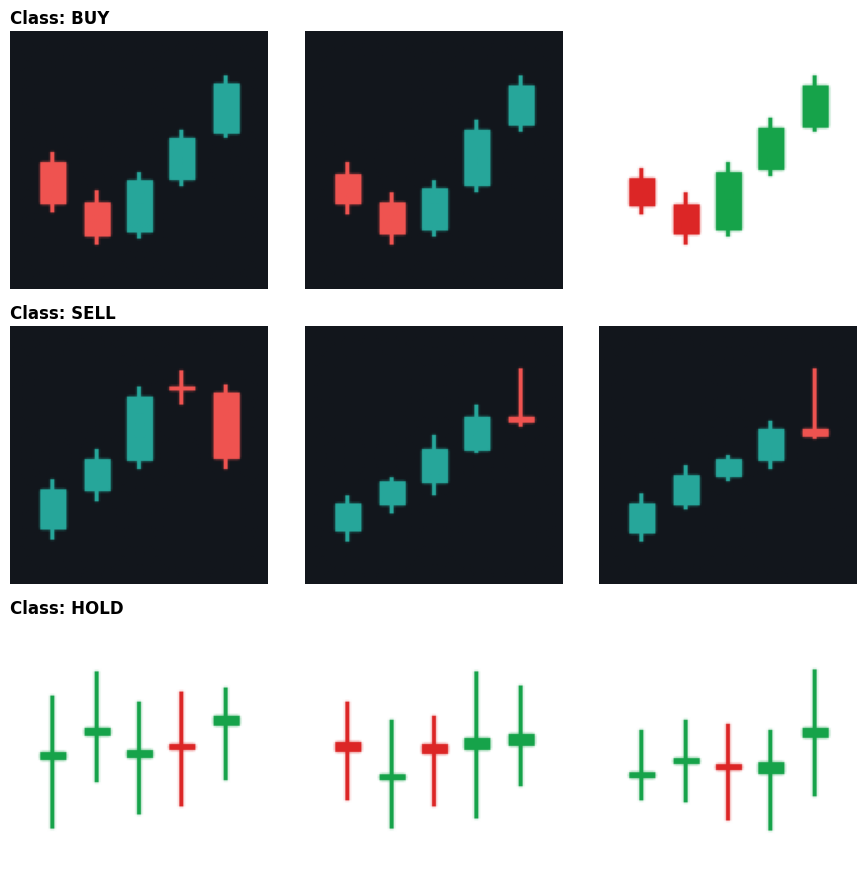

In [7]:
#Visualizing the data generated
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random

data_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'
classes = ['buy', 'sell', 'hold']

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for row_idx, cls in enumerate(classes):
  cls_folder = os.path.join(data_dir, cls)
  sample_files = random.sample(os.listdir(cls_folder), 3)
  for col_idx, file_name in enumerate(sample_files):
    img_path = os.path.join(cls_folder, file_name)
    img = mpimg.imread(img_path)
    ax = axes[row_idx, col_idx]
    ax.imshow(img)
    ax.axis('off')
    if col_idx == 0:
      ax.set_title(f"Class: {cls.upper()}", fontsize=12, fontweight='bold', loc='left')
plt.tight_layout()
plt.show()

In [21]:
import io
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
API_KEY = "5SSM7TV3NATANWD6"
base_dir = '/content/drive/MyDrive/candlestick_dataset'
for category in ['buy', 'hold', 'sell']:
  os.makedirs(os.path.join(base_dir, category), exist_ok=True)
print(f"Trget directory comfirmed at {base_dir}")
def render_and_save_tile(candles_tuple, label, source_name, index):
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  fig.patch.set_facecolor('#ffffff')
  ax.set_facecolor('#ffffff')
  for idx , (o, h, l, c) in enumerate(candles_tuple):
    color = '#16a34a' if c >= o else '#dc2626'
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    lower = min(o, c)
    height = max(abs(c - o), 0.15)
    rect = patches.Rectangle((idx - 0.28, lower), 0.56, height, facecolor=color, edgecolor=color, zorder=2)
    ax.add_patch(rect)
  all_lows = [x[2] for x in candles_tuple]
  all_highs = [x[1] for x in candles_tuple]
  pad = (max(all_highs) - min(all_lows)) * 0.15 + 0.5
  ax.set_ylim(min(all_lows) - pad, max(all_highs) + pad)
  ax.set_xlim(0.7, len(candles_tuple) - 0.3)
  ax.axis('off')
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.95)
  filepath = os.path.join(base_dir, label, f"{source_name}_{index}.png")
  fig.savefig(filepath, format='png', dpi=100, facecolor='#ffffff')
  plt.close(fig)


def fetch_alpha_vantage_data(ticker, api_key):
  url = f"https://www.alphavantage.co/query?function=TIME_SERIES_DAILY&symbol={ticker}&outputsize=full&apikey={API_KEY}"
  try:
    res = requests.get(url)
    data = res.json()
    df = pd.DataFrame.from_dict(data['Time Series (Daily)'], orient='index')
    df.index = pd.to_datetime(df.index)
    if "information" in df.columns or "Error Message" in df.columns or len (df.columns) <5 :
      return None
    df.rename(columns={
        'timestamp': 'Date', 'open':'Open', 'high':'High',
        'low': 'Low', 'close':'Close', 'volume':'Volume'

    }, inplace=True)
    df['Date'] = pd.to_datetime(df['Date'])
    df.sort_values('Date', inplace=True)
    df.set_index('Date', inplace=True)
    for col in ['Open', 'High', 'Low', 'Close', 'Volume']:
      df[col] = pd.to_numeric(df[col], errors='coerce')

    df.dropna(inplace=True)

    return df
  except Exception as e:
    print (f"Failed to fetch data for {ticker}: {e}")


Trget directory comfirmed at /content/drive/MyDrive/candlestick_dataset


In [22]:
#Watchlist Execution loop
watchlist = ["AAPL", "MSFT", "GOOGL", "TSLA"]
total_generated = 0

for ticker in watchlist:
  df_stock = fetch_alpha_vantage_data(ticker, API_KEY)


  if df_stock is not None and len(df_stock) >= 10:
    source_counts = {'buy':0, 'hold':0, 'sell':0}
    for i in range(5, len(df_stock) - 3):
      window = df_stock.iloc[i-5:i]
      future_close = df_stock.iloc[i + 3]['Close']
      current_close = window.iloc[-1]['Close']
      pct_change = (future_close - current_close) / current_close
      if pct_change > 0.005:
        label = 'buy'
      elif pct_change < -0.005:
        label = 'sell'
      else:
        label = 'hold'
        candles_tuple = list(window[['Open', 'High', 'Low', 'Close']].itertuples(index=False, name=None))
        render_and_save_tile(candles_tuple, label, ticker, i)
        source_counts[label] += 1
        total_generated += 1
    print (f" -> Generated | Buy: {saved_counts['buy']} | Hold: {saved_counts['hold']} | Sell:{saved_counts['sell']}")


Failed to fetch data for AAPL: 'Time Series (Daily)'
Failed to fetch data for MSFT: 'Time Series (Daily)'
Failed to fetch data for GOOGL: 'Time Series (Daily)'
Failed to fetch data for TSLA: 'Time Series (Daily)'


In [17]:
#Feeding the fetched data into the model
import tensorflow as tf
from tensorflow.keras.models import load_model

model = '/content/drive/MyDrive/cnn_candlestick_model_augmented.keras'
model = load_model(model)

print ("Model loaded successfully")
class_names = ['buy', 'hold', 'sell']
if not market_data.empty and len(market_data) >= 5:
  recent_candles = market_data.tail(5)
  candles_tuple = [(row['Open'], row['High'], row['Low'], row['Close']) for _, row in recent_candles.iterrows()]
  #REndering into memory buffer
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  fig.patch.set_facecolor('#ffffff')
  ax.set_facecolor('#ffffff')
  for idx, (o, h, l, c) in enumerate(candles_tuple):
    color = '#16a34a' if c>= o else '#dc2626'
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    lower = min(o, c)
    height = max(abs(c - o), 0.15)
    rect = patches.Rectangle((idx - 0.28, lower), 0.56, height, facecolor=color, edgecolor=color, zorder=2)
    ax.add_patch(rect)
  all_lows = [x[2] for x in candles_tuple]
  all_highs = [x[1] for x in candles_tuple]
  pad = (max(all_highs) - min(all_lows)) * 0.15 + 0.5
  ax.set_ylim(min(all_lows) - pad, max(all_highs) + pad)
  ax.set_xlim(-0.7, len(candles_tuple) - 0.3)
  ax.axis('off')
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
  buf = io.BytesIO()
  fig.savefig(buf, format='png', dpi=100, facecolor='#ffffff')
  buf.seek(0)
  plt.close(fig)

  #Predicting the data to buy/sell/hold
  img = tf.keras.utils.load_img(buf, target_size=(128, 128))
  img_array = tf.expand_dims(tf.keras.utils.img_to_array(img), 0)

  preds = model.predict(img_array) [0]
  best_idx = preds.argmax()
  print (f"\n Signals for {ticker_symbol}: {class_names[best_idx].upper()} ({preds[best_idx] * 100:.2f}%)")





Model loaded successfully
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step

 Signals for NVDA: HOLD (100.00%)


In [ ]:
#Notification tab
import io
import smtplib
from email.mime.text import MIMEText
from email.mime.multipart import MIMEMultipart
from email.mime.image import MIMEImage
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import requests
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model

#Email configuration


In [10]:
import os

data_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'

print("📊 Verifying all files in your dataset folders:")
total_files = 0
for cls in ['buy', 'sell', 'hold']:
    cls_path = os.path.join(data_dir, cls)
    if os.path.exists(cls_path):
        files = os.listdir(cls_path)
        print(f"📂 {cls}/ -> {len(files)} total images found")
        total_files += len(files)
    else:
        print(f"⚠️ Folder missing: {cls}")

print(f"\n🎉 Grand Total across all classes: {total_files} images ready for training!")

📊 Verifying all files in your dataset folders:
📂 buy/ -> 200 total images found
📂 sell/ -> 200 total images found
📂 hold/ -> 200 total images found

🎉 Grand Total across all classes: 600 images ready for training!


In [11]:
import os

model_path = '/content/drive/MyDrive/cnn_candlestick_model_augmented.keras'

if os.path.exists(model_path):
    print("✅ Model file found!")
else:
    print("⚠️ Model file not found at that path. You need to run your training cell first so it can save the model!")

✅ Model file found!
